In [21]:
import mlflow
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import normalize
import umap

In [3]:
df = pd.read_csv("../data/arxiv_papers_preprocessed_v2.csv")

In [5]:
def clean_spaces_embedding(text_string):
    cleaned = text_string.strip("[]")
    return np.fromstring(cleaned, sep=' ')


df['text_clean_embeddings'] = df['text_clean_embeddings'].apply(clean_spaces_embedding)

X = np.vstack(df['text_clean_embeddings'].values).astype('float32')

print("Forme finale de la matrice :", X.shape)

Forme finale de la matrice : (2000, 768)


In [8]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print(X_scaled[:2])

[[ 1.6021042   0.69093734 -1.1385304  ... -0.7987721  -0.16493836
  -0.79606473]
 [ 0.20039421  0.64546365  0.9301421  ...  0.2768133  -2.3077185
  -0.54432124]]


## First try ##

In [ ]:
mlflow.set_tracking_uri("http://127.0.0.1:5000")
mlflow.set_experiment("KMeans-clustering")

inertia_list = []
silhouette_list = []
k_range = range(2, 11)

with mlflow.start_run(run_name="StandarScaler_Without_DimensionReduction"):
    mlflow.log_params({"k_min": 2, "k_max": 10, "init": "k-means++", "n_init": 20, "random_state": 42})

    for k in k_range:
        with mlflow.start_run(run_name=f"k={k}", nested=True):
            model = KMeans(n_clusters=k, init="k-means++", n_init=20, random_state=42)
            labels = model.fit_predict(X_scaled)

            inertia = model.inertia_
            sil = silhouette_score(X_scaled, labels)

            mlflow.log_param("n_clusters", k)
            mlflow.log_metric("inertia", inertia)
            mlflow.log_metric("silhouette", sil)

            inertia_list.append(inertia)
            silhouette_list.append(sil)

2026/10/31 10:13:57 INFO mlflow.tracking.fluent: Experiment with name 'KMeans-clustering' does not exist. Creating a new experiment.


🏃 View run k=2 at: http://127.0.0.1:5000/#/experiments/1/runs/fb557ac128224264bcfe3d93c040d327
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run k=3 at: http://127.0.0.1:5000/#/experiments/1/runs/92918f14f05a49279e1ecf6c983246ae
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run k=4 at: http://127.0.0.1:5000/#/experiments/1/runs/6be8067f44684d7a8ed580c8579c3c9e
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run k=5 at: http://127.0.0.1:5000/#/experiments/1/runs/42e20c59fa1e4c30b47378509bd143f2
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run k=6 at: http://127.0.0.1:5000/#/experiments/1/runs/f576088406ba4ca893aa271af04ce4bb
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run k=7 at: http://127.0.0.1:5000/#/experiments/1/runs/0f420bd738374b6fbf8bfff54b3cfcb8
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run k=8 at: http://127.0.0.1:5000/#/experiments/1/runs/60d84e86

🏃 View run elbow_silhouette_plot at: http://127.0.0.1:5000/#/experiments/1/runs/f87c33f701804ff594759e8f31574cb6
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


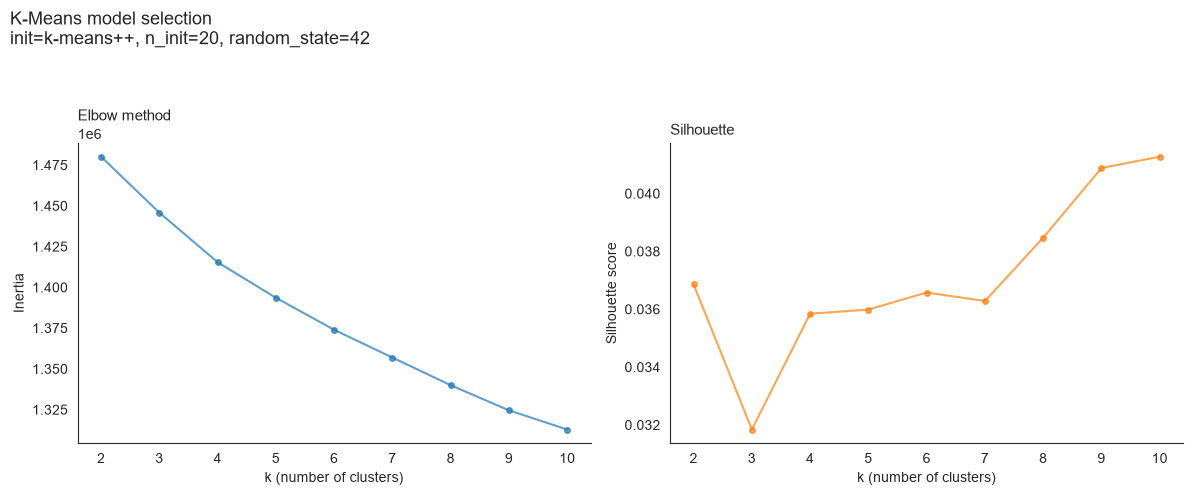

In [15]:
sns.set_style("white")
palette = sns.color_palette("tab10")

ks = list(k_range)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.plot(ks, inertia_list, marker="o", markersize=4, linewidth=1.5,
         alpha=0.7, color=palette[0])
ax2.plot(ks, silhouette_list, marker="o", markersize=4, linewidth=1.5,
         alpha=0.7, color=palette[1])

ax1.set(xlabel="k (number of clusters)", ylabel="Inertia")
ax2.set(xlabel="k (number of clusters)", ylabel="Silhouette score")
ax1.set_title("Elbow method", loc="left", fontsize=11)
ax2.set_title("Silhouette", loc="left", fontsize=11)

for ax in (ax1, ax2):
    ax.set_xticks(ks)
    sns.despine(ax=ax)

fig.suptitle("K-Means model selection\ninit=k-means++, n_init=20, random_state=42",
             x=0.01, ha="left", fontsize=13)

plt.tight_layout(rect=(0, 0, 1, 0.92))

with mlflow.start_run(run_name="elbow_silhouette_plot"):
    mlflow.log_figure(fig, "elbow_silhouette.png")

plt.show()

## Trying to solve problems ##

In [18]:
mlflow.set_tracking_uri("http://127.0.0.1:5000")
mlflow.set_experiment("KMeans-clustering")

sns.set_style("white")
palette = sns.color_palette("tab10")


def run(X, run_name, extra_params, k_range=range(2, 11)):
    ks = list(k_range)
    inertia_list, silhouette_list = [], []

    with mlflow.start_run(run_name=run_name):
        mlflow.log_params({"k_min": ks[0], "k_max": ks[-1], "init": "k-means++",
                           "n_init": 20, "random_state": 42, **extra_params})

        for k in ks:
            with mlflow.start_run(run_name=f"k={k}", nested=True):
                model = KMeans(n_clusters=k, init="k-means++", n_init=20, random_state=42)
                labels = model.fit_predict(X)

                inertia = model.inertia_
                sil = silhouette_score(X, labels)

                mlflow.log_param("n_clusters", k)
                mlflow.log_metric("inertia", inertia)
                mlflow.log_metric("silhouette", sil)

                inertia_list.append(inertia)
                silhouette_list.append(sil)

        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
        ax1.plot(ks, inertia_list, marker="o", markersize=4, linewidth=1.5,
                 alpha=0.7, color=palette[0])
        ax2.plot(ks, silhouette_list, marker="o", markersize=4, linewidth=1.5,
                 alpha=0.7, color=palette[1])

        ax1.set(xlabel="k (number of clusters)", ylabel="Inertia")
        ax2.set(xlabel="k (number of clusters)", ylabel="Silhouette score")
        ax1.set_title("Elbow method", loc="left", fontsize=11)
        ax2.set_title("Silhouette", loc="left", fontsize=11)
        for ax in (ax1, ax2):
            ax.set_xticks(ks)
            sns.despine(ax=ax)

        fig.suptitle(f"K-Means model selection: {run_name}\n"
                     "init=k-means++, n_init=20, random_state=42",
                     x=0.01, ha="left", fontsize=13)
        plt.tight_layout(rect=(0, 0, 1, 0.92))

        mlflow.log_figure(fig, "elbow_silhouette.png")
        plt.show()

    return inertia_list, silhouette_list

🏃 View run k=2 at: http://127.0.0.1:5000/#/experiments/1/runs/73e6b462498e48fc98103862310967fc
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run k=3 at: http://127.0.0.1:5000/#/experiments/1/runs/351237437dff48fdbcedfdac9dcb8670
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run k=4 at: http://127.0.0.1:5000/#/experiments/1/runs/97879695cd7b4960bfa8d3dd4dbca9f3
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run k=5 at: http://127.0.0.1:5000/#/experiments/1/runs/c7b303f73dde41d79f1206f35ea123de
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run k=6 at: http://127.0.0.1:5000/#/experiments/1/runs/2ae5211eb0bd4e64a31930056653586c
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run k=7 at: http://127.0.0.1:5000/#/experiments/1/runs/7428e99ced174d07b40d796739bc85cf
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run k=8 at: http://127.0.0.1:5000/#/experiments/1/runs/fb523ebe

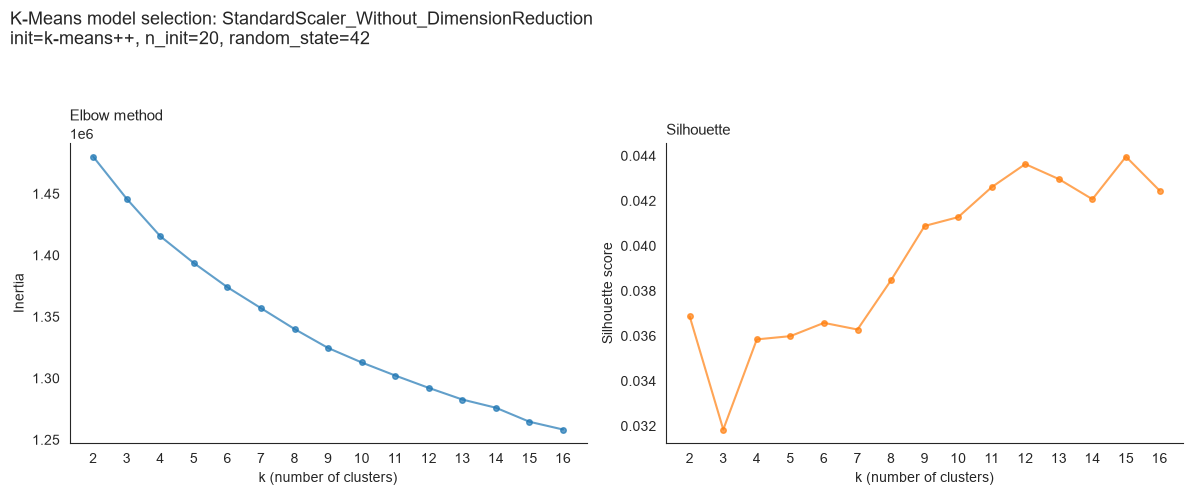

🏃 View run StandardScaler_Without_DimensionReduction at: http://127.0.0.1:5000/#/experiments/1/runs/d9d3b44eaaa84bfcaf5be71097665bd9
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


In [19]:
res_scaled = run(
    X_scaled,
    "StandardScaler_Without_DimensionReduction",
    {"preprocessing": "StandardScaler", "reduction": "none"},range(2, 17)
)

c:\Users\T14s\Arix-Research-Paper-Recommendation-System\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


🏃 View run k=2 at: http://127.0.0.1:5000/#/experiments/1/runs/cdefe19a3e8b4bcaafc05facac8deaee
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run k=3 at: http://127.0.0.1:5000/#/experiments/1/runs/e54e9cba0ea44fecb1cfdb6dba2399dd
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run k=4 at: http://127.0.0.1:5000/#/experiments/1/runs/8ba88c70632e4735b796dc3eb7f36aa4
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run k=5 at: http://127.0.0.1:5000/#/experiments/1/runs/d24cba1f30ad4535a83e4497aa0345f2
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run k=6 at: http://127.0.0.1:5000/#/experiments/1/runs/0ef7d1bbb9764b25970147483af3bd2e
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run k=7 at: http://127.0.0.1:5000/#/experiments/1/runs/d69a4c1f80494b3085cb600ebc15bbf4
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run k=8 at: http://127.0.0.1:5000/#/experiments/1/runs/28462982

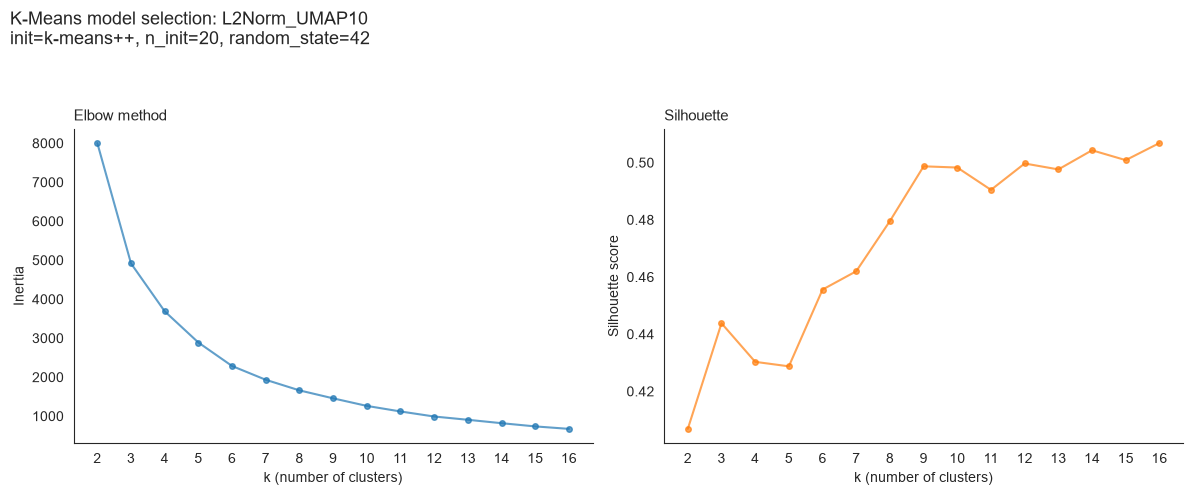

🏃 View run L2Norm_UMAP10 at: http://127.0.0.1:5000/#/experiments/1/runs/aa63c24c594e4be391f3f568b9c6925d
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


In [23]:
X_norm = normalize(X)
reducer = umap.UMAP(n_components=10, n_neighbors=15, min_dist=0.0,
                    metric="cosine", random_state=42)
X_umap = reducer.fit_transform(X_norm)

res_umap = run(
    X_umap,
    "L2Norm_UMAP10",
    {"preprocessing": "L2norm", "reduction": "UMAP", "umap_n_components": 10,
     "umap_n_neighbors": 15, "umap_min_dist": 0.0, "umap_metric": "cosine"},range(2, 17)
)

c:\Users\T14s\Arix-Research-Paper-Recommendation-System\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


🏃 View run kmeans_clusters_umap2d_k6_k9 at: http://127.0.0.1:5000/#/experiments/1/runs/3c36e725e5f3427da96c157e5166f570
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


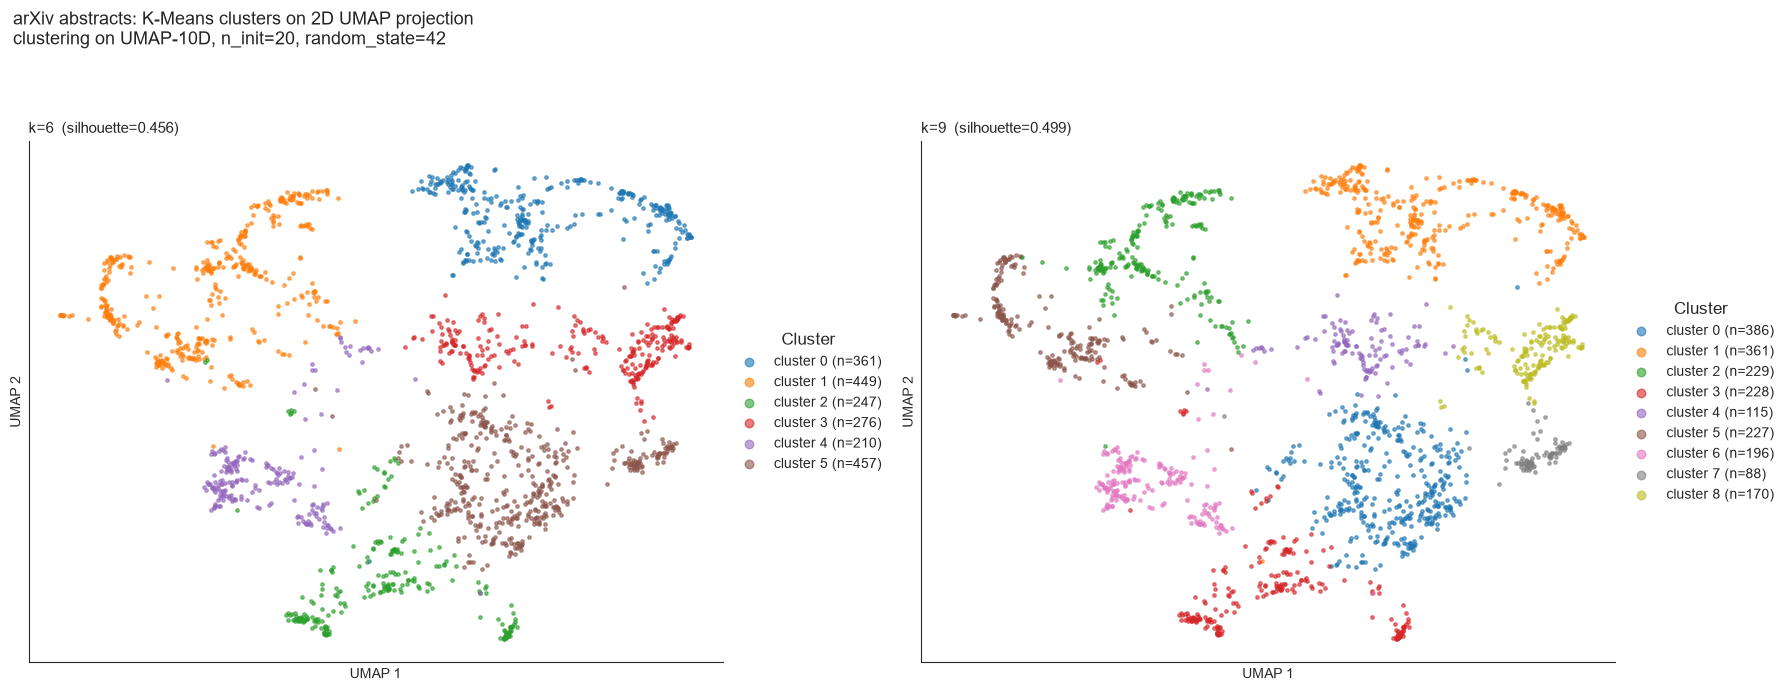

In [24]:
sns.set_style("white")

reducer_2d = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.0,
                       metric="cosine", random_state=42)
X_2d = reducer_2d.fit_transform(X_norm)


candidate_ks = [6, 9]
labels_by_k = {}
for k in candidate_ks:
    model = KMeans(n_clusters=k, init="k-means++", n_init=20, random_state=42)
    labels_by_k[k] = model.fit_predict(X_umap)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

for ax, k in zip(axes, candidate_ks):
    labels = labels_by_k[k]
    palette = sns.color_palette("tab10", n_colors=k)
    sil = silhouette_score(X_umap, labels)

    for c in range(k):
        mask = labels == c
        ax.scatter(X_2d[mask, 0], X_2d[mask, 1], s=6, alpha=0.6,
                   color=palette[c], label=f"cluster {c} (n={mask.sum()})")

    ax.set_title(f"k={k}  (silhouette={sil:.3f})", loc="left", fontsize=11)
    ax.set_xlabel("UMAP 1")
    ax.set_ylabel("UMAP 2")
    ax.set_xticks([])
    ax.set_yticks([])
    sns.despine(ax=ax)
    ax.legend(title="Cluster", frameon=False, loc="center left",
              bbox_to_anchor=(1.0, 0.5), markerscale=2.5,
              fontsize=10, title_fontsize=12)

fig.suptitle("arXiv abstracts: K-Means clusters on 2D UMAP projection\n"
             "clustering on UMAP-10D, n_init=20, random_state=42",
             x=0.01, ha="left", fontsize=13)
plt.tight_layout(rect=(0, 0, 1, 0.92))

with mlflow.start_run(run_name="kmeans_clusters_umap2d_k6_k9"):
    mlflow.log_params({"candidate_ks": str(candidate_ks),
                       "clustering_space": "UMAP10", "viz_space": "UMAP2",
                       "umap_n_neighbors": 15, "umap_min_dist": 0.0,
                       "umap_metric": "cosine"})
    mlflow.log_figure(fig, "kmeans_umap2d_k6_k9.png")

plt.show()

In [ ]:
out_dir = Path("../data")
out_dir.mkdir(exist_ok=True)

for k in [6, 9]:
    model = KMeans(n_clusters=k, init="k-means++", n_init=20, random_state=42)
    model.fit(X_umap)

    df_out = df.copy()
    df_out["cluster"] = model.labels_
    df_out.to_csv(out_dir / f"data_clustered_k{k}.csv", index=False)

    df_cent = pd.DataFrame(
        model.cluster_centers_,
        columns=[f"umap10_{i}" for i in range(model.cluster_centers_.shape[1])],
    )
    df_cent.insert(0, "cluster", np.arange(k))
    df_cent.to_csv(out_dir / f"centroids_k{k}.csv", index=False)